## CartPole Skating

> **Problem**: If Peter wants to escape from the wolf, he needs to be able to move faster than him. We will see how Peter can learn to skate, in particular, to keep balance, using Q-Learning.

First, let's install Gymnasium (with the `classic-control` extra) and import the required libraries:

In [1]:
import sys
!{sys.executable} -m pip install -q "gymnasium[classic-control]"

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import random

## Create a cartpole environment

In [2]:
env = gym.make("CartPole-v1", render_mode="human")
print(env.action_space)
print(env.observation_space)
print(env.action_space.sample())

Discrete(2)
Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
0


To see how the environment works, let's run a short simulation for 100 steps.

In [3]:
obs, info = env.reset()

for _ in range(100):
    action = env.action_space.sample()
    obs, rew, terminated, truncated, info = env.step(action)
    if terminated or truncated:
        obs, info = env.reset()

env.close()

During simulation, we need to get observations in order to decide how to act. In Gymnasium, `step()` returns current observations, a reward, `terminated` and `truncated` flags, and an `info` dictionary. An episode ends when either `terminated` or `truncated` is `True`:

In [4]:
env = gym.make("CartPole-v1", render_mode="human")
obs, info = env.reset()

terminated = False
truncated = False
while not (terminated or truncated):
    obs, rew, terminated, truncated, info = env.step(env.action_space.sample())
    print(f"{obs} -> {rew}")

env.close()

[ 0.02498116  0.19750677  0.01548098 -0.2773222 ] -> 1.0
[ 0.02893129  0.3924045   0.00993453 -0.5650825 ] -> 1.0
[ 0.03677938  0.58738565 -0.00136712 -0.85461915] -> 1.0
[ 0.0485271   0.39228237 -0.0184595  -0.5623664 ] -> 1.0
[ 0.05637274  0.19742425 -0.02970683 -0.27555582] -> 1.0
[ 0.06032123  0.00273846 -0.03521794  0.00761151] -> 1.0
[ 0.060376    0.19834732 -0.03506571 -0.29597178] -> 1.0
[ 0.06434295  0.39395118 -0.04098515 -0.5995044 ] -> 1.0
[ 0.07222196  0.58962184 -0.05297524 -0.9048102 ] -> 1.0
[ 0.0840144   0.3952558  -0.07107144 -0.62923753] -> 1.0
[ 0.09191952  0.5912938  -0.08365619 -0.94342965] -> 1.0
[ 0.10374539  0.7874372  -0.10252479 -1.2611821 ] -> 1.0
[ 0.11949414  0.98370993 -0.12774843 -1.5841347 ] -> 1.0
[ 0.13916834  0.790318   -0.15943111 -1.3338666 ] -> 1.0
[ 0.1549747   0.5975239  -0.18610846 -1.0950176 ] -> 1.0
[ 0.16692518  0.79454374 -0.2080088  -1.4398445 ] -> 1.0
[ 0.18281604  0.99153113 -0.23680569 -1.7896708 ] -> 1.0


We can get min and max value of those numbers:

In [5]:
print(env.observation_space.low)
print(env.observation_space.high)

[-4.8               -inf -0.41887903        -inf]
[4.8               inf 0.41887903        inf]


## State Discretization

In [6]:
def discretize(x):
    return tuple((x / np.array([0.25, 0.25, 0.01, 0.1])).astype(int).tolist())

Let's also explore other discretization method using bins:

In [7]:
def create_bins(i, num):
    return np.arange(num + 1) * (i[1] - i[0]) / num + i[0]

print("Sample bins for interval (-5,5) with 10 bins\n", create_bins((-5, 5), 10))

ints = [(-5, 5), (-2, 2), (-0.5, 0.5), (-2, 2)]  # intervals of values for each parameter
nbins = [20, 20, 10, 10]  # number of bins for each parameter
bins = [create_bins(ints[i], nbins[i]) for i in range(4)]

def discretize_bins(x):
    return tuple(int(np.digitize(x[i], bins[i])) for i in range(4))

Sample bins for interval (-5,5) with 10 bins
 [-5. -4. -3. -2. -1.  0.  1.  2.  3.  4.  5.]


Let's now run a short simulation and observe those discrete environment values.

In [8]:
env = gym.make("CartPole-v1")
obs, info = env.reset()

terminated = False
truncated = False
while not (terminated or truncated):
    obs, rew, terminated, truncated, info = env.step(env.action_space.sample())
    # print(discretize_bins(obs))
    print(discretize(obs))

env.close()

(0, 0, 1, -3)
(0, 1, 0, -5)
(0, 0, 0, -3)
(0, 0, 0, 0)
(0, 0, 0, -3)
(0, 0, -1, 0)
(0, 0, -1, 2)
(0, -1, 0, 5)
(0, -2, 0, 8)
(0, -1, 1, 5)
(0, 0, 2, 2)
(0, -1, 3, 5)
(0, -2, 4, 8)
(0, -3, 6, 11)
(0, -2, 8, 9)
(0, -3, 10, 12)
(0, -4, 13, 15)
(0, -3, 16, 13)
(0, -2, 18, 10)
(0, -1, 20, 8)
(0, -2, 22, 11)


## Q-Table Structure

In [9]:
Q = {}
actions = (0, 1)

def qvalues(state):
    return [Q.get((state, a), 0) for a in actions]

## Let's Start Q-Learning!

In [10]:
# hyperparameters
alpha = 0.3
gamma = 0.9
epsilon = 0.90

In [11]:
def probs(v, eps=1e-4):
    v = v - v.min() + eps
    v = v / v.sum()
    return v

env = gym.make("CartPole-v1")
Qmax = 0
Qbest = {}
cum_rewards = []
rewards = []

for epoch in range(100000):
    obs, info = env.reset()
    terminated = False
    truncated = False
    cum_reward = 0

    # == do the simulation ==
    while not (terminated or truncated):
        s = discretize(obs)
        if random.random() < epsilon:
            # exploitation - choose an action according to Q-Table probabilities
            v = probs(np.array(qvalues(s)))
            a = random.choices(actions, weights=v)[0]
        else:
            # exploration - choose a random action
            a = random.choice(actions)

        obs, rew, terminated, truncated, info = env.step(a)
        cum_reward += rew
        ns = discretize(obs)
        future_q = 0 if terminated else max(qvalues(ns))
        Q[(s, a)] = (1 - alpha) * Q.get((s, a), 0) + alpha * (rew + gamma * future_q)

    cum_rewards.append(cum_reward)
    rewards.append(cum_reward)

    # == Periodically print results and calculate average reward ==
    if (epoch + 1) % 5000 == 0:
        avg_reward = np.mean(cum_rewards)
        print(f"{epoch + 1}: {avg_reward:.2f}, alpha={alpha}, epsilon={epsilon}")
        if avg_reward > Qmax:
            Qmax = avg_reward
            Qbest = Q.copy()
        cum_rewards = []

env.close()

5000: 85.25, alpha=0.3, epsilon=0.9
10000: 123.77, alpha=0.3, epsilon=0.9
15000: 141.89, alpha=0.3, epsilon=0.9
20000: 154.58, alpha=0.3, epsilon=0.9
25000: 171.17, alpha=0.3, epsilon=0.9
30000: 184.52, alpha=0.3, epsilon=0.9
35000: 186.98, alpha=0.3, epsilon=0.9
40000: 191.82, alpha=0.3, epsilon=0.9
45000: 198.96, alpha=0.3, epsilon=0.9
50000: 197.15, alpha=0.3, epsilon=0.9
55000: 199.60, alpha=0.3, epsilon=0.9
60000: 191.09, alpha=0.3, epsilon=0.9
65000: 195.18, alpha=0.3, epsilon=0.9
70000: 198.00, alpha=0.3, epsilon=0.9
75000: 196.00, alpha=0.3, epsilon=0.9
80000: 194.42, alpha=0.3, epsilon=0.9
85000: 188.19, alpha=0.3, epsilon=0.9
90000: 185.90, alpha=0.3, epsilon=0.9
95000: 192.09, alpha=0.3, epsilon=0.9
100000: 189.29, alpha=0.3, epsilon=0.9


## Plotting Training Progress

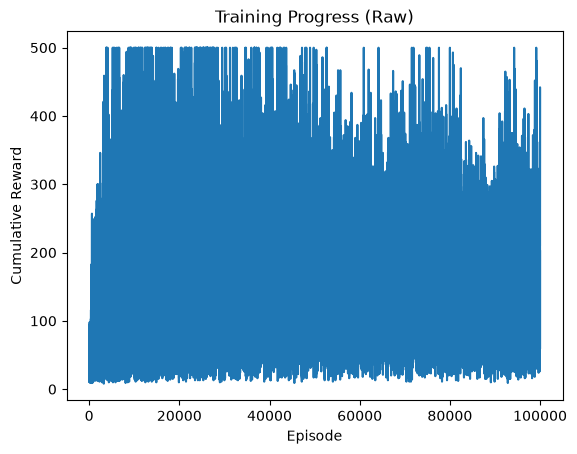

In [12]:
plt.plot(rewards)
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Training Progress (Raw)")
plt.show()

From this graph, it is not possible to tell anything, because due to the nature of stochastic training process the length of training sessions varies greatly. To make more sense of this graph, we can calculate **running average** over series of experiments, let's say 100. This can be done conveniently using `np.convolve`:

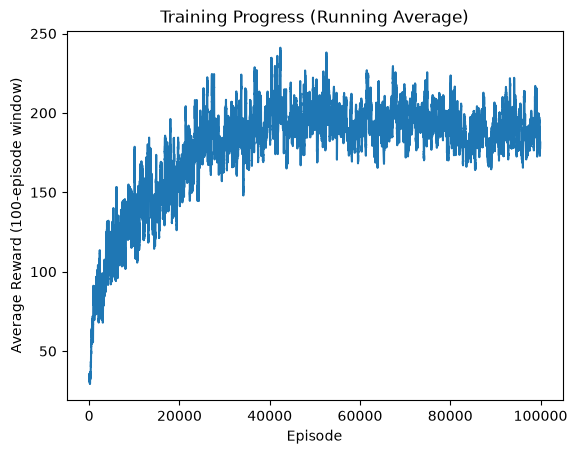

In [13]:
def running_average(x, window):
    return np.convolve(x, np.ones(window) / window, mode="valid")

plt.plot(running_average(rewards, 100))
plt.xlabel("Episode")
plt.ylabel("Average Reward (100-episode window)")
plt.title("Training Progress (Running Average)")
plt.show()

## Varying Hyperparameters and Seeing the Result in Action

Now it would be interesting to actually see how the trained model behaves. Let's run the simulation, and we will be following the same action selection strategy as during training: sampling according to the probability distribution in Q-Table:

In [14]:
env = gym.make("CartPole-v1", render_mode="human")
obs, info = env.reset()
terminated = False
truncated = False

while not (terminated or truncated):
    s = discretize(obs)
    v = probs(np.array(qvalues(s)))
    a = random.choices(actions, weights=v)[0]
    obs, _, terminated, truncated, info = env.step(a)

env.close()

## Evaluating the Trained Policy

Let's evaluate `Qbest` greedily (selecting the action with the highest Q-value at each step) across 100 independent episodes and compare the average reward against `CartPole-v1`'s registered reward threshold of 475 (maximum 500):

In [15]:
eval_env = gym.make("CartPole-v1")
eval_rewards = []

for episode in range(100):
    obs, info = eval_env.reset(seed=episode)
    terminated = False
    truncated = False
    total_reward = 0

    while not (terminated or truncated):
        s = discretize(obs)
        a = int(np.argmax([Qbest.get((s, act), 0) for act in actions]))
        obs, rew, terminated, truncated, info = eval_env.step(a)
        total_reward += rew

    eval_rewards.append(total_reward)

eval_env.close()
print(f"Average evaluation reward over 100 episodes: {np.mean(eval_rewards):.2f}")
print(f"Min: {np.min(eval_rewards):.0f}, Max: {np.max(eval_rewards):.0f}")

Average evaluation reward over 100 episodes: 306.43
Min: 92, Max: 500


## Saving result to an animated GIF

If you want to impress your friends, you may want to send them the animated GIF picture of the balancing pole. In Gymnasium, pass `render_mode="rgb_array"` when creating the environment so `env.render()` returns RGB image frames, and then save them to an animated GIF using the PIL library (saved to the system temp directory so running the notebook does not overwrite the repository's `images/cartpole-balance.gif`):

In [16]:
import os
import tempfile
from PIL import Image

gif_env = gym.make("CartPole-v1", render_mode="rgb_array")
obs, info = gif_env.reset()
terminated = False
truncated = False
i = 0
ims = []

while not (terminated or truncated):
    s = discretize(obs)
    img = gif_env.render()
    ims.append(Image.fromarray(img))
    v = probs(np.array([Qbest.get((s, a), 0) for a in actions]))
    a = random.choices(actions, weights=v)[0]
    obs, _, terminated, truncated, info = gif_env.step(a)
    i += 1

gif_env.close()
gif_path = os.path.join(tempfile.gettempdir(), "cartpole-balance.gif")
ims[0].save(gif_path, save_all=True, append_images=ims[1::2], loop=0, duration=5)
print(f"Saved {i} frames to {gif_path}")